# Electron Configurations from the Math Up: Statistics, Differential Equations, Linear Algebra

**Colin Casey, 2026.** Where "1s² 2s² 2p⁶ …" comes from, in four kinds of math, plus a floating-point warning.

| Section | Math | Question |
|---|---|---|
| 0. $2.0 + 10^{-20}$ | floating point vs exact arithmetic | Why does the computer say $2.0 + 10^{-20} = 2.0$? |
| 1. The hydrogen atom as a differential equation | ODEs (SymPy) | Where do $n$, $l$ and $E_n = -13.6/n^2$ eV come from? |
| 2. The same equation as a matrix | linear algebra (eigenvalues) | Can a computer find the energy levels without solving anything by hand? |
| 3. Filling the orbitals | counting, Pauli exclusion | Why do shells hold $2n^2$ electrons, and in what order do they fill? |
| 4. Statistics of electrons | Fermi-Dirac distribution | Why one electron per state, and what does temperature do? |
| 5. Lean 4 | proofs | Shell capacities and microstate counts, certified |

Kernel: **py312**.

In [1]:
import sys, subprocess, pathlib, math
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal
sp.init_printing(use_latex='mathjax')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"])})

---
## 0. $2.0 + 10^{-20}$: floating point vs exact arithmetic

**In plain words.** A computer's ordinary numbers (IEEE 754 double precision, `float64`) keep about 16 significant digits. Near 2.0, the gap between neighbouring representable numbers is $4.4\times10^{-16}$. Anything smaller than half that gap simply vanishes when added: $2.0 + 10^{-20}$ rounds back to exactly $2.0$. SymPy uses exact rationals, so it keeps the $10^{-20}$.

**Why it matters here:** energy levels that differ by tiny amounts (fine structure, near-degenerate states) can be erased by rounding. Know your precision before trusting a small difference.

In [2]:
print('float64:  2.0 + 1e-20 == 2.0  ->', 2.0 + 1e-20 == 2.0)
print('machine epsilon (gap above 1.0):', sys.float_info.epsilon)
print('gap above 2.0 (one ULP):        ', np.spacing(2.0))
print('smallest x with 2.0 + x != 2.0:  about', np.spacing(2.0)/2, '(half a ULP, round-to-nearest-even)')
exact = sp.Integer(2) + sp.Rational(1, 10**20)
display(sp.Eq(sp.Symbol('2 + 10^{-20}'), exact))
print('SymPy exact: (2 + 1e-20) - 2 =', exact - 2)
print('mpmath, 30 digits:', sp.N(exact, 30))

float64:  2.0 + 1e-20 == 2.0  -> True
machine epsilon (gap above 1.0): 2.220446049250313e-16
gap above 2.0 (one ULP):         4.440892098500626e-16
smallest x with 2.0 + x != 2.0:  about 2.220446049250313e-16 (half a ULP, round-to-nearest-even)


                200000000000000000001
2 + 10__{-20} = ─────────────────────
                100000000000000000000

SymPy exact: (2 + 1e-20) - 2 = 1/100000000000000000000
mpmath, 30 digits: 2.00000000000000000001000000000


---
## 1. The hydrogen atom as a differential equation

Separate the Schrödinger equation in spherical coordinates, $\psi = R_{nl}(r)\,Y_{lm}(\theta,\phi)$, and set $u = rR$. In atomic units (lengths in Bohr radii $a_0$, energies in Hartree, $1\ \text{Ha} = 27.211$ eV) the radial equation is
$$-\frac12 u'' + \left[\frac{l(l+1)}{2r^2} - \frac Zr\right]u = E\,u$$
The integer $l$ comes from the angular part (the $Y_{lm}$); the integer $n$ comes from requiring $u$ to stay finite at infinity. SymPy checks the textbook solutions and their energies $E_n = -Z^2/(2n^2)$ Ha.

In [3]:
r = sp.symbols('r', positive=True)
Z = sp.symbols('Z', positive=True)
def radial_residual(u, l, E):
    return sp.simplify(-sp.Rational(1, 2)*sp.diff(u, r, 2) + (l*(l + 1)/(2*r**2) - Z/r)*u - E*u)

solutions = {                       # (n, l): u(r) = r R_nl(r), unnormalized
    (1, 0): r*sp.exp(-Z*r),
    (2, 0): r*(2 - Z*r)*sp.exp(-Z*r/2),
    (2, 1): r**2*sp.exp(-Z*r/2),
    (3, 2): r**3*sp.exp(-Z*r/3),
}
for (n_, l_), u in solutions.items():
    E = -Z**2/(2*n_**2)
    print(f'n = {n_}, l = {l_}:  residual of the radial ODE with E = -Z^2/(2 n^2):', radial_residual(u, l_, E))
print('\nhydrogen (Z = 1):', ', '.join(f'E_{n_} = {float(-27.211386/(2*n_**2)):.3f} eV' for n_ in (1, 2, 3)))
print('-> the energy depends on n only, not on l: the "accidental" degeneracy of the 1/r potential')

n = 1, l = 0:  residual of the radial ODE with E = -Z^2/(2 n^2): 0
n = 2, l = 0:  residual of the radial ODE with E = -Z^2/(2 n^2): 0
n = 2, l = 1:  residual of the radial ODE with E = -Z^2/(2 n^2): 0
n = 3, l = 2:  residual of the radial ODE with E = -Z^2/(2 n^2): 0

hydrogen (Z = 1): E_1 = -13.606 eV, E_2 = -3.401 eV, E_3 = -1.512 eV
-> the energy depends on n only, not on l: the "accidental" degeneracy of the 1/r potential


---
## 2. The same equation as a matrix (linear algebra)

Put $u$ on a grid $r_i = ih$ and replace $u''$ by the finite difference $(u_{i+1} - 2u_i + u_{i-1})/h^2$. The ODE becomes the **matrix eigenvalue problem** $H\mathbf u = E\mathbf u$ with a symmetric tridiagonal $H$: diagonal $1/h^2 + V(r_i)$, off-diagonal $-1/(2h^2)$. Its eigenvalues are the energy levels, no hand-solving required. The grid spacing sets the accuracy: the error falls like $h^2$.

 l  lowest eigenvalues (Hartree)                       exact -1/(2n^2)
 0   -0.49995   -0.12500   -0.05555   -0.03125     -0.50000   -0.12500   -0.05556   -0.03125
 1   -0.12500   -0.05556   -0.03125   -0.02000     -0.12500   -0.05556   -0.03125   -0.02000
 2   -0.05556   -0.03125   -0.02000   -0.01360     -0.05556   -0.03125   -0.02000   -0.01389
(the n = 6, l = 2 value is a little high: that orbital reaches ~70 Bohr and is squeezed by the 80-Bohr grid edge; a bigger box fixes it: -0.01389)

ground-state error vs grid spacing: convergence order 1.98 (finite differences: 2)


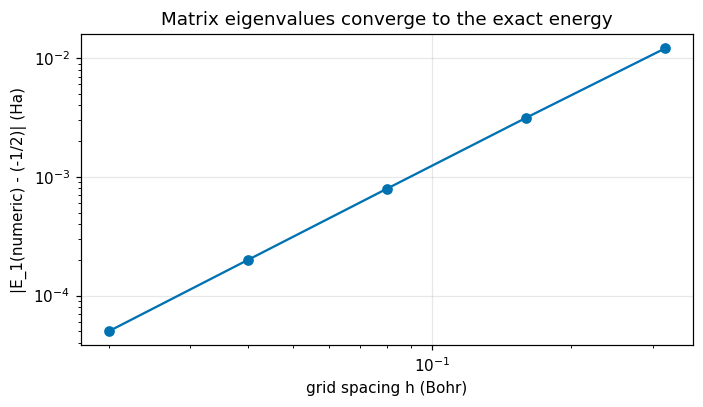

Figure: on log-log axes the error falls on a straight line of slope about 2 as the grid gets finer.


In [4]:
def levels(l, Zv=1.0, rmax=80.0, N=4000, k=4):
    h = rmax/(N + 1)
    rr = h*np.arange(1, N + 1)
    diag = 1/h**2 + l*(l + 1)/(2*rr**2) - Zv/rr
    off = -0.5/h**2*np.ones(N - 1)
    return eigh_tridiagonal(diag, off, select='i', select_range=(0, k - 1))[0]

print(f'{"l":>2s}  lowest eigenvalues (Hartree)                       exact -1/(2n^2)')
for l_ in range(3):
    E_num = levels(l_)
    exact_ = [-1/(2*n_**2) for n_ in range(l_ + 1, l_ + 5)]
    print(f'{l_:2d}  ' + '  '.join(f'{e:9.5f}' for e in E_num) + '    ' + '  '.join(f'{e:9.5f}' for e in exact_))

print('(the n = 6, l = 2 value is a little high: that orbital reaches ~70 Bohr and is squeezed by the 80-Bohr grid edge;'
      ' a bigger box fixes it:', f'{levels(2, rmax=200.0, N=10000)[3]:.5f})')
Ns = [250, 500, 1000, 2000, 4000]
errs = [abs(levels(0, N=N_, k=1)[0] + 0.5) for N_ in Ns]
hs = [80/(N_ + 1) for N_ in Ns]
order = np.polyfit(np.log(hs), np.log(errs), 1)[0]
print(f'\nground-state error vs grid spacing: convergence order {order:.2f} (finite differences: 2)')
plt.figure(figsize=(6.5, 3.8))
plt.loglog(hs, errs, 'o-'); plt.xlabel('grid spacing h (Bohr)'); plt.ylabel('|E_1(numeric) - (-1/2)| (Ha)')
plt.title('Matrix eigenvalues converge to the exact energy'); plt.tight_layout(); plt.show()
print('Figure: on log-log axes the error falls on a straight line of slope about 2 as the grid gets finer.')

---
## 3. Filling the orbitals: counting and the Pauli exclusion principle

**Capacity.** For each $l$ there are $2l + 1$ values of $m$, and each holds 2 electrons (spin up and down): a subshell holds $2(2l+1)$, so s, p, d, f hold 2, 6, 10, 14. A shell $n$ has $l = 0, \dots, n-1$, so it holds $\sum_{l=0}^{n-1}2(2l+1) = 2n^2$.

**Order (Madelung rule).** In real atoms the inner electrons screen the nucleus, which breaks the hydrogen degeneracy: subshells fill in order of increasing $n + l$, and for equal $n + l$ the smaller $n$ first. That gives 1s 2s 2p 3s 3p **4s 3d** 4p … A handful of elements break even this rule (Cr, Cu, and others), because half-filled and filled d subshells are extra stable.

In [5]:
nn, ll = sp.symbols('n l', integer=True, nonnegative=True)
display(sp.Eq(sp.Sum(2*(2*ll + 1), (ll, 0, nn - 1)), sp.factor(sp.summation(2*(2*ll + 1), (ll, 0, nn - 1)))))

LETTER = 'spdfghi'
ORDER = sorted(((n_, l_) for n_ in range(1, 8) for l_ in range(n_)), key=lambda t: (t[0] + t[1], t[0]))
SUP = str.maketrans('0123456789', '⁰¹²³⁴⁵⁶⁷⁸⁹')
def configuration(Zv):
    left, parts = Zv, []
    for n_, l_ in ORDER:
        if left == 0: break
        k_ = min(left, 2*(2*l_ + 1)); left -= k_
        parts.append(f'{n_}{LETTER[l_]}{str(k_).translate(SUP)}')
    return ' '.join(parts)
print('filling order:', ' '.join(f'{n_}{LETTER[l_]}' for n_, l_ in ORDER[:15]))
names = {1: 'H', 2: 'He', 6: 'C', 8: 'O', 10: 'Ne', 11: 'Na', 18: 'Ar', 19: 'K', 24: 'Cr', 26: 'Fe', 29: 'Cu', 30: 'Zn', 36: 'Kr'}
for Zv, el in names.items():
    note = {24: '   (real: [Ar] 3d⁵ 4s¹, half-filled d)', 29: '   (real: [Ar] 3d¹⁰ 4s¹, filled d)'}.get(Zv, '')
    print(f'{el:>2s} (Z = {Zv:2d}): {configuration(Zv)}{note}')

n - 1                 
 ___                  
 ╲                    
  ╲                  2
  ╱   (4⋅l + 2) = 2⋅n 
 ╱                    
 ‾‾‾                  
l = 0                 

filling order: 1s 2s 2p 3s 3p 4s 3d 4p 5s 4d 5p 6s 4f 5d 6p
 H (Z =  1): 1s¹
He (Z =  2): 1s²
 C (Z =  6): 1s² 2s² 2p²
 O (Z =  8): 1s² 2s² 2p⁴
Ne (Z = 10): 1s² 2s² 2p⁶
Na (Z = 11): 1s² 2s² 2p⁶ 3s¹
Ar (Z = 18): 1s² 2s² 2p⁶ 3s² 3p⁶
 K (Z = 19): 1s² 2s² 2p⁶ 3s² 3p⁶ 4s¹
Cr (Z = 24): 1s² 2s² 2p⁶ 3s² 3p⁶ 4s² 3d⁴   (real: [Ar] 3d⁵ 4s¹, half-filled d)
Fe (Z = 26): 1s² 2s² 2p⁶ 3s² 3p⁶ 4s² 3d⁶
Cu (Z = 29): 1s² 2s² 2p⁶ 3s² 3p⁶ 4s² 3d⁹   (real: [Ar] 3d¹⁰ 4s¹, filled d)
Zn (Z = 30): 1s² 2s² 2p⁶ 3s² 3p⁶ 4s² 3d¹⁰
Kr (Z = 36): 1s² 2s² 2p⁶ 3s² 3p⁶ 4s² 3d¹⁰ 4p⁶


**Counting microstates (statistics).** How many ways can $k$ electrons sit in a subshell with $g = 2(2l+1)$ spin-orbitals? Electrons are identical and at most one per spin-orbital (Pauli), so the answer is a combination, $\binom{g}{k}$. Carbon's $2p^2$: $\binom{6}{2} = 15$ microstates. **Hund's rule** says the ground state puts them in different orbitals with parallel spins.

In [6]:
for label, g, kk in (('C 2p²', 6, 2), ('N 2p³', 6, 3), ('O 2p⁴', 6, 4), ('Fe 3d⁶', 10, 6)):
    print(f'{label:7s}: C({g}, {kk}) = {math.comb(g, kk)} microstates')
print('note C(6, 2) = C(6, 4): two electrons and two holes in a p subshell are counted the same way')

C 2p²  : C(6, 2) = 15 microstates
N 2p³  : C(6, 3) = 20 microstates
O 2p⁴  : C(6, 4) = 15 microstates
Fe 3d⁶ : C(10, 6) = 210 microstates
note C(6, 2) = C(6, 4): two electrons and two holes in a p subshell are counted the same way


---
## 4. Statistics of electrons: the Fermi-Dirac distribution

Because no two electrons can share a state, the average occupation of a state at energy $E$ and temperature $T$ is the **Fermi-Dirac** distribution, never above 1:
$$f_{FD}(E) = \frac{1}{e^{(E - \mu)/k_BT} + 1}$$
Compare bosons (Bose-Einstein, $-1$ in the denominator, no limit on occupation) and the classical limit (Maxwell-Boltzmann, $e^{-(E-\mu)/k_BT}$). At $T \to 0$ Fermi-Dirac becomes a step: every state below $\mu$ filled, every state above empty, which is exactly the "fill from the bottom" picture of section 3.

             1     
f_{FD} = ──────────
          E - μ    
          ─────    
          k_BT     
         ℯ      + 1

f_FD at E = mu: 1/2
f_FD(mu + d) + f_FD(mu - d) = 1  (the curve is symmetric about mu)
classical limit, E - mu >> kT: f_FD / f_MB -> 1
T -> 0 below mu: 1   above mu: 0


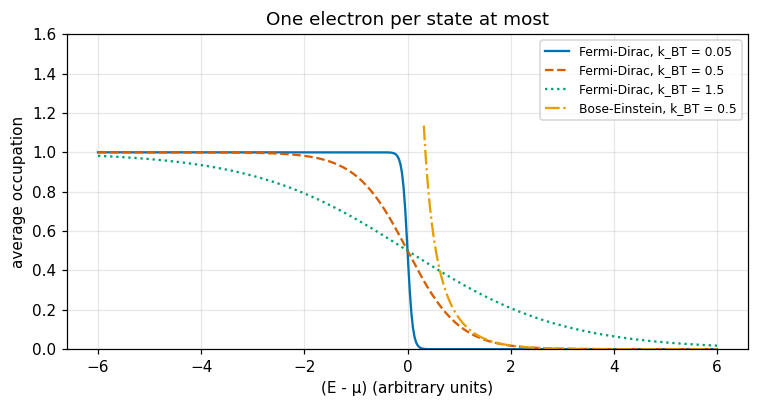

Figure: the Fermi-Dirac curves all pass through 1/2 at E = μ and never exceed 1; colder curves are sharper steps. The Bose-Einstein curve rises above 1 as E approaches μ.


In [7]:
E_, mu = sp.symbols('E mu', real=True)
kT = sp.symbols('k_BT', positive=True)
f_FD = 1/(sp.exp((E_ - mu)/kT) + 1)
f_BE = 1/(sp.exp((E_ - mu)/kT) - 1)
f_MB = sp.exp(-(E_ - mu)/kT)
display(sp.Eq(sp.Symbol('f_{FD}'), f_FD))
print('f_FD at E = mu:', sp.simplify(f_FD.subs(E_, mu)))
print('f_FD(mu + d) + f_FD(mu - d) =', sp.simplify(f_FD.subs(E_, mu + kT*sp.Symbol('d')) + f_FD.subs(E_, mu - kT*sp.Symbol('d'))),
      ' (the curve is symmetric about mu)')
print('classical limit, E - mu >> kT: f_FD / f_MB ->', sp.limit(f_FD/f_MB, E_, sp.oo))
print('T -> 0 below mu:', sp.limit(f_FD.subs(E_, mu - 1), kT, 0, '+'), '  above mu:', sp.limit(f_FD.subs(E_, mu + 1), kT, 0, '+'))

xx = np.linspace(-6, 6, 400)
plt.figure(figsize=(7, 3.8))
for kTv, ls in ((0.05, '-'), (0.5, '--'), (1.5, ':')):
    plt.plot(xx, 1/(np.exp(xx/kTv) + 1), ls, label=f'Fermi-Dirac, k_BT = {kTv}')
plt.plot(xx[xx > 0.3], 1/(np.exp(xx[xx > 0.3]/0.5) - 1), '-.', label='Bose-Einstein, k_BT = 0.5')
plt.ylim(0, 1.6); plt.xlabel('(E - μ) (arbitrary units)'); plt.ylabel('average occupation'); plt.legend(fontsize=8)
plt.title('One electron per state at most'); plt.tight_layout(); plt.show()
print('Figure: the Fermi-Dirac curves all pass through 1/2 at E = μ and never exceed 1; colder curves are sharper steps. '
      'The Bose-Einstein curve rises above 1 as E approaches μ.')

---
## 5. Lean 4: shell capacities and microstate counts

Core Lean proves the counting facts for every case it is given: subshell capacities, the $2n^2$ shell rule for shells 1 to 10, the first steps of the Madelung order, and the microstate counts (with a binomial coefficient defined from Pascal's rule).

In [8]:
lean_src = r'''
-- capacity of a subshell with angular momentum l
def subshell (l : Nat) : Nat := 2 * (2 * l + 1)
theorem spdf : (subshell 0, subshell 1, subshell 2, subshell 3) = (2, 6, 10, 14) := by decide

-- shell capacity: sum over l = 0 .. n-1 equals 2 n^2, checked for shells 1..10
def shell (n : Nat) : Nat := ((List.range n).map subshell).foldl (· + ·) 0
theorem two_n_squared : (List.range 10).all (fun k => shell (k + 1) == 2 * (k + 1) ^ 2) = true := by decide

-- binomial coefficient by Pascal's rule, and Pauli microstate counts
def choose : Nat → Nat → Nat
  | _, 0 => 1
  | 0, _ + 1 => 0
  | n + 1, k + 1 => choose n k + choose n (k + 1)
theorem carbon_p2 : choose 6 2 = 15 := by decide
theorem particle_hole : choose 6 2 = choose 6 4 ∧ choose 10 6 = choose 10 4 := by decide

-- Madelung order: sort subshells by (n + l, n); the first 8 are 1s 2s 2p 3s 3p 4s 3d 4p
def madelungKey (p : Nat × Nat) : Nat := 10 * (p.1 + p.2) + p.1
theorem madelung_first_eight :
    let order := [(1,0), (2,0), (2,1), (3,0), (3,1), (4,0), (3,2), (4,1)]
    (order.zip order.tail).all (fun (a, b) => madelungKey a < madelungKey b) = true := by decide

-- noble gases: cumulative capacities along the Madelung order give 2, 10, 18, 36
theorem noble_gases : (2 : Nat) = 2 ∧ 2 + 2 + 6 = 10 ∧ 10 + 2 + 6 = 18 ∧ 18 + 2 + 10 + 6 = 36 := by decide
'''
lean_file = pathlib.Path.cwd() / 'electron_configuration.lean'
lean_file.write_text(lean_src.strip() + '\n', encoding='utf-8')
print(lean_src.strip())
res = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
print(f'\n{lean_file.name}: {lean_src.count("theorem ")} theorems, exit code {res.returncode}')
print('✓ verified by the Lean kernel' if res.returncode == 0 else (res.stdout + res.stderr))

-- capacity of a subshell with angular momentum l
def subshell (l : Nat) : Nat := 2 * (2 * l + 1)
theorem spdf : (subshell 0, subshell 1, subshell 2, subshell 3) = (2, 6, 10, 14) := by decide

-- shell capacity: sum over l = 0 .. n-1 equals 2 n^2, checked for shells 1..10
def shell (n : Nat) : Nat := ((List.range n).map subshell).foldl (· + ·) 0
theorem two_n_squared : (List.range 10).all (fun k => shell (k + 1) == 2 * (k + 1) ^ 2) = true := by decide

-- binomial coefficient by Pascal's rule, and Pauli microstate counts
def choose : Nat → Nat → Nat
  | _, 0 => 1
  | 0, _ + 1 => 0
  | n + 1, k + 1 => choose n k + choose n (k + 1)
theorem carbon_p2 : choose 6 2 = 15 := by decide
theorem particle_hole : choose 6 2 = choose 6 4 ∧ choose 10 6 = choose 10 4 := by decide

-- Madelung order: sort subshells by (n + l, n); the first 8 are 1s 2s 2p 3s 3p 4s 3d 4p
def madelungKey (p : Nat × Nat) : Nat := 10 * (p.1 + p.2) + p.1
theorem madelung_first_eight :
    let order := [(1,0), (2,0), (2,1), 


electron_configuration.lean: 6 theorems, exit code 0
✓ verified by the Lean kernel


---
## Summary

- **Floating point:** $2.0 + 10^{-20} = 2.0$ in `float64` (one ULP at 2.0 is $4.4\times10^{-16}$); SymPy keeps the exact $2 + 10^{-20}$.
- **Differential equations:** the radial ODE gives integer $n$ and $l$, and $E_n = -Z^2/(2n^2)$ Ha, the same for every $l$ in hydrogen.
- **Linear algebra:** discretizing the ODE turns it into a tridiagonal eigenvalue problem whose eigenvalues converge to the exact energies at order $h^2$.
- **Counting:** $2(2l+1)$ per subshell, $2n^2$ per shell; the Madelung $(n + l, n)$ order gives real configurations (with known exceptions like Cr and Cu).
- **Statistics:** Pauli exclusion is why microstates are combinations, and why electrons follow Fermi-Dirac statistics: at most one per state.

## References

[1] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018, ch. 4 (hydrogen) and ch. 5 (identical particles).

[2] R. D. Knight, *Physics for Scientists and Engineers: A Strategic Approach with Modern Physics*, 5th ed. Pearson, 2023, ch. 41 (atomic physics).

[3] *IEEE Standard for Floating-Point Arithmetic*, IEEE Std 754-2019, 2019.

[4] G. Strang, *Introduction to Linear Algebra*, 5th ed. Wellesley, MA, USA: Wellesley-Cambridge Press, 2016.

*Reference details are from memory (chapter numbers especially); verify before citing.*